# Project 04 — Lunar Terrain Instance Segmentation
### From pixels to masks: a reproducible YOLO11 learning experiment

**Aim:** train a crater/terrain instance-segmentation model, audit annotation quality, compare image resolutions fairly, inspect segmentation mistakes, and evaluate **once** on held-out test images.

**Dataset:** Kaggle `umaimak/moon-instance-segmentation`, Roboflow Lunar Terrain Segmentation v3 (YOLO format). The supplied YAML identifies **four classes**: `crater`, `rock`, `uneven surface`, `lunar artifacts`.

**The notebook is designed for Kaggle with a GPU enabled and Internet on for the Ultralytics installation / pretrained weights.** Run from top to bottom; allow time for two training runs. Training experiments are educational, not an assessment of lunar mission readiness.

**Key rule:** training set fits weights; validation set compares model choices; test set is evaluated **only once** after model selection.

## Concept refresher 1 — How image prediction works

- **Pixel:** numbers representing image colour/brightness. CNN layers learn filters that respond to edges, textures and increasingly complex patterns.
- **CNN (convolutional neural network):** extracts spatial patterns by applying learned filters over small local regions.
- **Neural-network weights:** numerical parameters changed during training by backpropagation to reduce the **loss** between predicted boxes/classes/masks and annotated ground truth.
- **Transfer learning:** start with a pretrained YOLO11n segmentation model, then fine-tune it to four lunar categories.
- **Inference (prediction):** show a new image; the network outputs **boxes**, **class labels**, **confidence scores**, and **pixel masks**. Ground truth is **not used** during prediction.

In [1]:
from pathlib import Path
import importlib.util, subprocess, sys, shutil, csv
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

if importlib.util.find_spec("ultralytics") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
from ultralytics import YOLO

SOURCE = Path("/kaggle/input/datasets/umaimak/moon-instance-segmentation/Lunar Terrain Segmentation.v3i.yolov11")
WORK = Path("/kaggle/working/lunar_project_04")
WORK.mkdir(parents=True, exist_ok=True)
assert SOURCE.exists(), "Attach the Kaggle dataset umaimak/moon-instance-segmentation first"
print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")
print("Original config:\n", (SOURCE / "data.yaml").read_text()[:1500])

GPU: True Tesla T4
Original config:
 train: ../train/images
val: ../valid/images
test: ../test/images

nc: 4
names: ['crater', 'rock', 'uneven surface', 'lunar artifacts']

roboflow:
  workspace: aerolite
  project: lunar-terrain-segmentation
  version: 3
  license: CC BY 4.0
  url: https://universe.roboflow.com/aerolite/lunar-terrain-segmentation/dataset/3


## 1 — Dataset quality audit **before training**

**Important discovery from the first five-epoch run:** The YAML names only class IDs **0–3**, yet some annotation files use class **4**. Its real meaning is unknown; **we must not silently relabel it as another object**.

Our conservative approach: **exclude entire image/label pairs containing any out-of-range class ID** from this four-class experiment. Other images remain unchanged. We record counts for each split. This is a defensible workaround for a learning experiment, not a repair of the source dataset; it may alter class balance and does not establish what class 4 means.

Also exclude malformed polygons and missing annotations rather than supplying incorrect labels. The original read-only Kaggle files are never modified.

In [2]:
CLASSES = ["crater", "rock", "uneven surface", "lunar artifacts"]
SPLITS = {"train": "train", "val": "valid", "test": "test"}
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png"}
records = []
for split, folder in SPLITS.items():
    image_dir = SOURCE / folder / "images"
    label_dir = SOURCE / folder / "labels"
    for image in sorted(image_dir.iterdir()):
        if image.suffix.lower() not in VALID_EXTENSIONS:
            continue
        label = label_dir / (image.stem + ".txt")
        status = "ok"
        ids = []
        if not label.is_file():
            status = "missing_annotation"
        else:
            try:
                for line in label.read_text().splitlines():
                    parts = line.strip().split()
                    if not parts:
                        continue
                    cls = int(parts[0])
                    xy = [float(z) for z in parts[1:]]
                    ids.append(cls)
                    if cls < 0 or cls >= len(CLASSES):
                        status = "invalid_class"
                    elif len(xy) < 6 or len(xy) % 2 or not np.isfinite(xy).all() or min(xy) < 0 or max(xy) > 1:
                        if status == "ok": status = "malformed_polygon"
            except (ValueError, OSError):
                status = "malformed_annotation"
        records.append({"split": split, "image": str(image), "label": str(label), "status": status, "objects": len(ids), "class_ids": ids})

audit = pd.DataFrame(records)
print("Dataset audit (image counts):")
display(pd.crosstab(audit["split"], audit["status"]))
print("All annotation IDs and their object counts:")
print(Counter(k for ids in audit["class_ids"] for k in ids))
print("Rejected images:", int((audit.status != "ok").sum()))
assert (audit.query('split == "train" and status == "ok"').shape[0] > 100)
assert (audit.query('split == "val" and status == "ok"').shape[0] > 10)

Dataset audit (image counts):


status,invalid_class,ok
split,,
test,1,173
train,32,1345
val,2,287


All annotation IDs and their object counts:
Counter({1: 3674, 0: 2499, 3: 1266, 2: 700, 4: 36})
Rejected images: 35


In [3]:
# Copy VALID image/annotation pairs to writable Kaggle working space.
# This avoids training on invalid class IDs and permits annotation caches.
CLEAN_ROOT = WORK / "filtered_dataset"
for split in SPLITS:
    (CLEAN_ROOT / split / "images").mkdir(parents=True, exist_ok=True)
    (CLEAN_ROOT / split / "labels").mkdir(parents=True, exist_ok=True)

for row in audit.itertuples(index=False):
    if row.status != "ok":
        continue
    dest_img = CLEAN_ROOT / row.split / "images" / Path(row.image).name
    dest_lab = CLEAN_ROOT / row.split / "labels" / Path(row.label).name
    if not dest_img.exists(): shutil.copy2(row.image, dest_img)
    if not dest_lab.exists(): shutil.copy2(row.label, dest_lab)

YAML = WORK / "lunar_filtered.yaml"
YAML.write_text(
    f"path: '{CLEAN_ROOT}'\n"
    "train: train/images\nval: val/images\ntest: test/images\n"
    "names:\n  0: crater\n  1: rock\n  2: uneven surface\n  3: lunar artifacts\n"
)
print("Data config:", YAML)
print(YAML.read_text())
assert all((CLEAN_ROOT / sp / "images").exists() for sp in SPLITS)

Data config: /kaggle/working/lunar_project_04/lunar_filtered.yaml
path: '/kaggle/working/lunar_project_04/filtered_dataset'
train: train/images
val: val/images
test: test/images
names:
  0: crater
  1: rock
  2: uneven surface
  3: lunar artifacts



## 2 — Look at images and their annotations

One annotation line has the form `class_id x1 y1 x2 y2 ...`, where coordinates are **normalised** to [0, 1]. Each polygon represents an individual object. We visualise examples before asking a model to learn them.

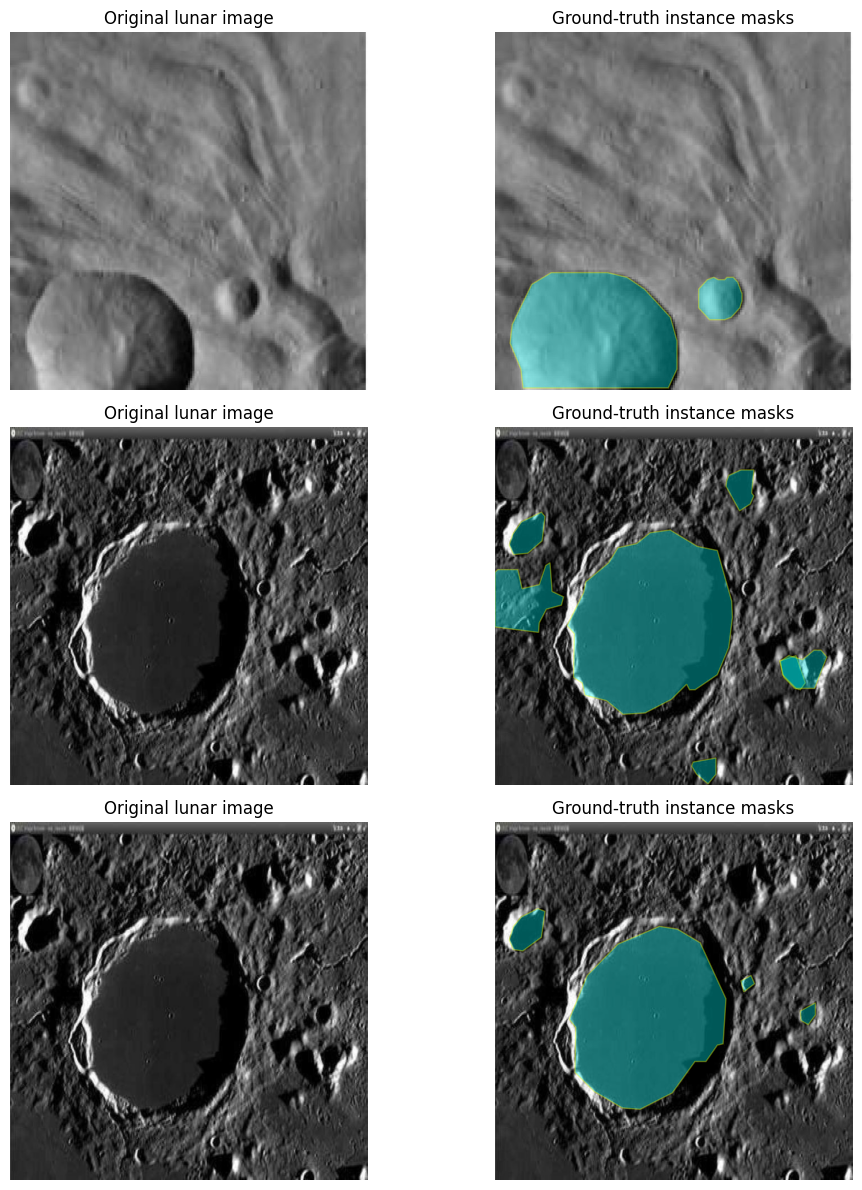

In [4]:
from matplotlib.patches import Polygon

samples = audit.query('split == "train" and status == "ok"').head(3)
fig, ax = plt.subplots(len(samples), 2, figsize=(11, 4 * len(samples)))
for j, row in enumerate(samples.itertuples(index=False)):
    im = plt.imread(row.image)
    h, w = im.shape[:2]
    ax[j, 0].imshow(im)
    ax[j, 0].set_title("Original lunar image")
    ax[j, 1].imshow(im)
    for ln in Path(row.label).read_text().splitlines():
        p = ln.split()
        if not p: continue
        pts = np.array([float(v) for v in p[1:]]).reshape(-1, 2)
        pts[:, 0] *= w; pts[:, 1] *= h
        ax[j, 1].add_patch(Polygon(pts, fill=True, facecolor="cyan", edgecolor="yellow", alpha=.35))
    ax[j, 1].set_title("Ground-truth instance masks")
    for a in ax[j]: a.axis("off")
plt.tight_layout(); plt.show()

## Concept refresher 2 — Epoch, precision, recall, IoU, mAP

- **Epoch:** one pass through the training dataset. More epochs can improve learning **or** eventually overfit.
- **Precision = TP/(TP+FP):** of the predicted objects matched at a chosen IoU/confidence operating point, how many are correct?
- **Recall = TP/(TP+FN):** of all annotated objects, how many were detected?
- **IoU (intersection over union):** overlap area of predicted and true masks divided by their combined area (0 = none; 1 = perfect).
- **Mask mAP50:** area under precision–recall performance averaged across categories with mask IoU **≥ 0.50**; **not pixel accuracy** and **not mean IoU**.
- **Mask mAP50–95:** a stricter summary averaging IoU thresholds from .50 to .95. Higher is better.

We will report **per-class** metrics too: a model can perform well on *uneven surface* while missing *craters*.

## 3 — Controlled improvement: image resolution

**Question:** Does increasing input resolution help detect smaller craters and improve mask boundaries?

We'll compare **two runs with identical** architecture, pretrained weights, random seed, training duration and standard augmentation. Only `imgsz` changes: **320 vs 512**. This is a controlled *input-representation* experiment, not proof of the causal effect in all settings. Both runs use the same filtered dataset and validation split.

**Practical note:** Two 20-epoch runs may take several minutes each, even on a T4 GPU. Increase/decrease `EPOCHS` uniformly for both runs if needed. Do not restart training while another cell is executing. Changing `imgsz` can affect memory/runtime substantially.

In [5]:
DEVICE = 0 if torch.cuda.is_available() else "cpu"
EPOCHS = 20
BATCH = 8
SEED = 42
RUNS = WORK / "training_runs"

experiment_results = {}
for resolution in [320, 512]:
    name = f"yolo11n_img{resolution}_e{EPOCHS}"
    print(f"\n======== Training {name} ========")
    seg = YOLO("yolo11n-seg.pt")  # fresh, identical pretrained starting point
    seg.train(
        data=str(YAML), epochs=EPOCHS, imgsz=resolution, batch=BATCH,
        device=DEVICE, seed=SEED, deterministic=True,
        project=str(RUNS), name=name, exist_ok=True,
        workers=2, plots=True, patience=EPOCHS,
    )
    best = RUNS / name / "weights" / "best.pt"
    assert best.exists(), f"Missing saved weights: {best}"
    experiment_results[resolution] = {"best_weights": str(best), "run_dir": str(RUNS / name)}
    print("Saved weights:", best)

print("Both experiments finished.")


======== Training yolo11n_img320_e20 ========
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/lunar_project_04/lunar_filtered.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_sca

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/20      0.51G      1.326      2.779      1.644      1.233          0          4        320: 100% ━━━━━━━━━━━━ 169/169 10.7it/s 15.8s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 7.5it/s 2.4s0.1s
                   all        287       1594      0.371      0.481      0.342      0.183      0.353      0.448      0.308      0.152

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
       3/20      0.51G       1.33      2.729      1.551      1.224          0         30        320: 100% ━━━━━━━━━━━━ 169/169 10.6it/s 15.9s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 7.5it/s 2.4s0.1s
                   all        287       1594      0.499      0.418      0.418      0.249      0.476      0.392      0.387   

## 4 — Compare validation results

The **validation** images guide which resolution we choose. We measure mask quality on held-out validation images (not training images). The reported mAP is based on model predictions and annotations; it is not a classification accuracy percentage.

In [6]:
validation_rows = []
for resolution, entry in experiment_results.items():
    fitted = YOLO(entry["best_weights"])
    metrics = fitted.val(data=str(YAML), split="val", imgsz=resolution, batch=BATCH,
                         device=DEVICE, plots=False, verbose=False)
    validation_rows.append({
        "imgsz": resolution,
        "Box_mAP50": float(metrics.box.map50),
        "Mask_mAP50": float(metrics.seg.map50),
        "Mask_mAP50_95": float(metrics.seg.map),
        "Mask_precision": float(metrics.seg.mp),
        "Mask_recall": float(metrics.seg.mr),
        "best_weights": entry["best_weights"],
    })
validation_df = pd.DataFrame(validation_rows).sort_values("imgsz").reset_index(drop=True)
display(validation_df.drop(columns="best_weights").round(3))

# Predeclare the selection criterion; don't cherry-pick a qualitative-looking example.
winner = validation_df.sort_values(["Mask_mAP50_95", "Mask_mAP50"], ascending=False).iloc[0]
BEST_RESOLUTION = int(winner.imgsz)
BEST_WEIGHTS = winner.best_weights
print("Selected on validation Mask mAP50-95:", BEST_RESOLUTION, BEST_WEIGHTS)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n-seg summary (fused): 114 layers, 2,850,196 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1634.6±606.4 MB/s, size: 55.2 KB)
val: Scanning /kaggle/working/lunar_project_04/filtered_dataset/val/labels.cache... 287 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 287/287 92.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 15.4it/s 2.3s0.2s
                   all        287       1594      0.678      0.572      0.598      0.427      0.652      0.555      0.561      0.389
Speed: 0.3ms preprocess, 2.6ms inference, 0.0ms loss, 1.4ms postprocess per image
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n-seg summary (fused): 114 layers, 2,850,196 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image acce

,imgsz,Box_mAP50,Mask_mAP50,Mask_mAP50_95,Mask_precision,Mask_recall
0,320,0.598,0.561,0.389,0.652,0.555
1,512,0.609,0.591,0.415,0.659,0.581


Selected on validation Mask mAP50-95: 512 /kaggle/working/lunar_project_04/training_runs/yolo11n_img512_e20/weights/best.pt


## 5 — Qualitative prediction versus ground truth

A predicted mask is a per-object region generated by the model. **Confidence** indicates how strongly the model favours the detection; it is **not the percentage of pixels correct**. Compare predicted boundaries with human-provided annotations and look for omissions and false positives.

Images shown here are from **validation**, not the reserved test split.

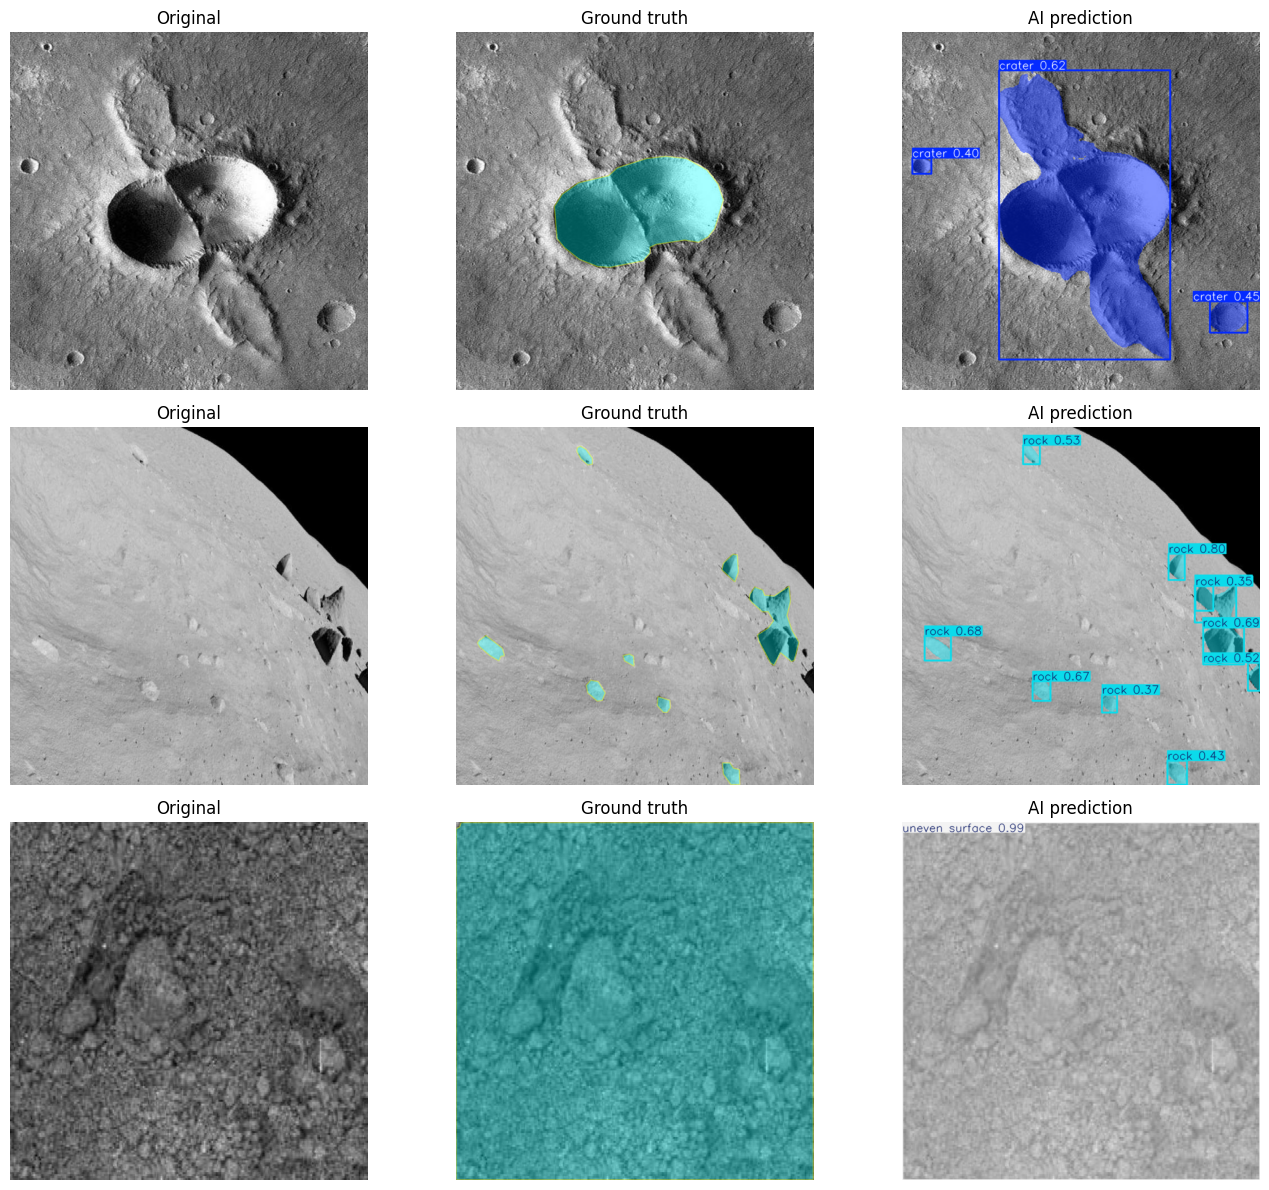

In [7]:
best_model = YOLO(BEST_WEIGHTS)
val_images = sorted((CLEAN_ROOT / "val" / "images").glob("*.jpg"))
assert len(val_images) >= 3
chosen = [val_images[i] for i in np.linspace(0, len(val_images)-1, 3, dtype=int)]
fig, axes = plt.subplots(len(chosen), 3, figsize=(14, 4 * len(chosen)))
for j, imgpath in enumerate(chosen):
    im = plt.imread(imgpath)
    h, w = im.shape[:2]
    labpath = CLEAN_ROOT / "val" / "labels" / (imgpath.stem + ".txt")
    pred = best_model.predict(str(imgpath), imgsz=BEST_RESOLUTION, conf=.25,
                              device=DEVICE, verbose=False)[0]
    axes[j, 0].imshow(im); axes[j, 0].set_title("Original")
    axes[j, 1].imshow(im); axes[j, 1].set_title("Ground truth")
    for line in labpath.read_text().splitlines():
        parts=line.split()
        if not parts: continue
        xy = np.asarray(list(map(float, parts[1:]))).reshape(-1, 2)
        xy[:,0]*=w; xy[:,1]*=h
        axes[j, 1].add_patch(Polygon(xy, closed=True, facecolor="cyan",
                                      edgecolor="yellow", alpha=.35))
    axes[j, 2].imshow(pred.plot()[:, :, ::-1]); axes[j, 2].set_title("AI prediction")
    for a in axes[j]: a.axis("off")
plt.tight_layout(); plt.show()

## 6 — Independent test evaluation (run once)

At this stage the architecture and resolution have been selected using **validation** results. We now perform a final test evaluation **once**, without using it to change the model. The test set is supplied by the dataset publisher; it is not necessarily free of near-duplicate scenes relative to training, and we have not independently audited provenance.

**No more tuning after reading test results** if you want to preserve this as an honest held-out evaluation.

In [8]:
final_metrics = best_model.val(data=str(YAML), split="test", imgsz=BEST_RESOLUTION,
                               batch=BATCH, device=DEVICE, plots=True, verbose=False)
final_scores = pd.Series({
    "Test Box mAP50": float(final_metrics.box.map50),
    "Test Mask mAP50": float(final_metrics.seg.map50),
    "Test Mask mAP50–95": float(final_metrics.seg.map),
    "Test Mask precision": float(final_metrics.seg.mp),
    "Test Mask recall": float(final_metrics.seg.mr),
})
display(final_scores.to_frame("Score").round(3))
print("Per-class mask mAP50:")
for i, score in enumerate(final_metrics.seg.ap50):
    print(CLASSES[i], f"{float(score):.3f}")

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n-seg summary (fused): 114 layers, 2,850,196 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1464.3±294.6 MB/s, size: 66.3 KB)
val: Scanning /kaggle/working/lunar_project_04/filtered_dataset/test/labels... 173 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 173/173 986.9it/s 0.2s0.2s
val: New cache created: /kaggle/working/lunar_project_04/filtered_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 6.5it/s 3.4s<0.1s
                   all        173       1038      0.699      0.581      0.614      0.439      0.686       0.58      0.603      0.409
Speed: 1.8ms preprocess, 5.3ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /kaggle/working/runs/segment/val-3


,Score
Test Box mAP50,0.614
Test Mask mAP50,0.603
Test Mask mAP50–95,0.409
Test Mask precision,0.686
Test Mask recall,0.580


Per-class mask mAP50:
crater 0.456
rock 0.469
uneven surface 0.898
lunar artifacts 0.590


## 7 — Save artefacts and a final run summary

The trained `.pt` file is **not merely Python code**; it contains learned model weights. Export the best model and key metrics. In Kaggle, use **Save Version** and check the Output tab. The resulting file is suitable for resuming inference later, provided the correct Ultralytics runtime is installed.

In [9]:
EXPORT = Path("/kaggle/working/lunar_project_04_best.pt")
shutil.copy2(BEST_WEIGHTS, EXPORT)
validation_df.drop(columns="best_weights").to_csv(WORK / "validation_comparison.csv", index=False)
final_scores.to_csv(WORK / "test_summary.csv", header=True)
print("Best model:", EXPORT)
print("Validation comparison:", WORK / "validation_comparison.csv")
print("Test summary:", WORK / "test_summary.csv")
print("Model bytes:", EXPORT.stat().st_size)

Best model: /kaggle/working/lunar_project_04_best.pt
Validation comparison: /kaggle/working/lunar_project_04/validation_comparison.csv
Test summary: /kaggle/working/lunar_project_04/test_summary.csv
Model bytes: 6015268


## 8 — What we learned, and what we cannot conclude

1. **Image → CNN → prediction:** pixels are numbers, learned convolutions extract spatial features, and YOLO predicts each object's class, confidence, bounding box and mask.
2. **Segmentation is not classification:** a correct object label can still have a poor boundary. We use mask IoU and mAP, not plain accuracy.
3. **Precision versus recall:** raising confidence thresholds may reduce false detections but miss real small craters.
4. **More pixels may help or hurt:** we tested whether resolution 512 improves mask mAP compared with 320 at the same epoch count.
5. **Dataset integrity matters:** out-of-range class-4 annotations were **excluded and counted**, not silently reassigned. A genuine fix requires knowing their class semantics from the dataset creator.
6. **Limitations:** brief model-selection exercise, limited dataset curation, possible near-duplicate scenes, and model performance restricted to benchmark imagery.

**Bridge to the solar filament competition:** next we must read the competition's evaluation metric and annotation type. A solar filament may require separating thin, connected structures; YOLO11 instance segmentation is a baseline possibility, but not automatically the best architecture.
